In [18]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
def sigmoid(S):
    return 1 / (1 + np.exp(-S))
def tanh(S):
    return (np.exp(S) - np.exp(-S)) / (np.exp(S) + np.exp(-S))
def Prob(X, w):
    return sigmoid(X.dot(w))
def loss(w, X, y, lam):
    z = Prob(X, w)
    return -np.mean(y * np.log(z) + (1 - y) * np.log(1 - z)) + lam * 0.5 /X.shape[0] * np.sum(w**2)

In [15]:
def logistic_regression(w_init, X, y, lam = 0.001, lr = 0.1, nepoches = 2000):
    N, d = X.shape[0], X.shape[1]
    w = w_old = w_init
    loss_hist = [loss(w, X, y, lam)]
    ep = 0
    while ep < nepoches:
        ep += 1
        mix_ids = np.random.permutation(N)
        for i in mix_ids:
            xi = X[i]
            yi = y[i]
            zi = sigmoid(xi.dot(w))
            w = w - lr * ((zi - yi) * xi + lam * w)
        loss_hist.append(loss(w, X, y, lam))
        if np.linalg.norm(w - w_old)/d < 1e-6:
            break
        w_old = w
    return w, loss_hist

In [17]:
X = np.array([[0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50]]).T
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
N = X.shape[0]
Xbar = np.concatenate((np.ones((N, 1)), X), axis = 1)
w_init = np.random.randn(Xbar.shape[1])
lam = 0.0001
w, loss_hist = logistic_regression(w_init, Xbar, y, lam, lr = 0.05, nepoches = 500)
print(w)
print(loss(w, Xbar, y, lam))

[-4.07854655  1.54718835]
0.4024127460349565


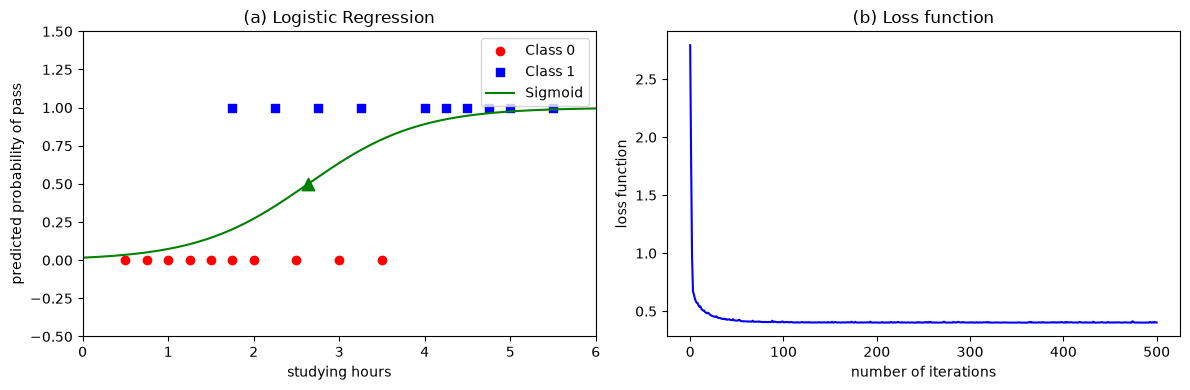

In [21]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(X[y == 0], y[y == 0],
            color='red', marker='o', label='Class 0')
plt.scatter(X[y == 1], y[y == 1],
            color='blue', marker='s', label='Class 1')
X_plot = np.linspace(0, 6, 200).reshape(-1, 1)
X_plot_bar = np.concatenate(
    (np.ones((X_plot.shape[0], 1)), X_plot),
    axis=1
)

y_plot = Prob(X_plot_bar, w)
plt.plot(X_plot, y_plot, color='green', label='Sigmoid')
x_threshold = -w[0] / w[1]

plt.scatter(x_threshold, 0.5,
            color='green', marker='^', s=80)

plt.xlabel('studying hours')
plt.ylabel('predicted probability of pass')
plt.title('(a) Logistic Regression')
plt.axis([0, 6, -0.5, 1.5])
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(loss_hist, color='blue')

plt.xlabel('number of iterations')
plt.ylabel('loss function')
plt.title('(b) Loss function')

plt.tight_layout()
plt.show()